<a href="https://colab.research.google.com/github/mwangimarie43-art/100-days-ai-journey/blob/main/assignment4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 4 Assignment: Descriptive Statistics and Relationships

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# Creating sample data relevant to a real estate or housing project
np.random.seed(42)
data = {
    'SquareFootage': np.random.normal(2000, 500, 100).astype(int),
    'HouseAge': np.random.randint(1, 50, 100),
    'SalePrice': [],
    'DistanceToCenter': np.random.uniform(1, 20, 100)
}

# Generate price based on square footage and age with some random noise
for sf, age in zip(data['SquareFootage'], data['HouseAge']):
    price = (sf * 150) - (age * 1000) + np.random.normal(50000, 20000)
    data['SalePrice'].append(max(50000, int(price)))

df = pd.DataFrame(data)
display(df.head())


,SquareFootage,HouseAge,SalePrice,DistanceToCenter
0,2248,9,402407,8.685654
1,1930,37,299475,17.867632
2,2323,33,357959,17.167641
3,2761,42,396325,18.777065
4,1882,44,272989,15.921472


focusing on three numerical variables relevant to this project:
- `SquareFootage` (Size of the house in sq ft)
- `SalePrice` (Sale price in USD)
- `HouseAge` (Age of the house in years)

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

selected_vars = ['SquareFootage', 'SalePrice', 'HouseAge']

stats_summary = {}
for var in selected_vars:
    values = df [var]
    stats_summary[var] = {
        'Mean': values.mean(),
        'Median': values.median(),
        'Range': values.max() - values.min(),
        'Variance': values.var(),
        'Std Dev': values.std()
    }

stats_df = pd.DataFrame(stats_summary)
display(stats_df)

,SquareFootage,SalePrice,HouseAge
Mean,1947.560000,3.188222e+05,24.560000
Median,1936.000000,3.200830e+05,24.500000
Range,2236.000000,3.516030e+05,48.000000
Variance,206183.723636,4.940479e+09,223.461010
Std Dev,454.074579,7.028854e+04,14.948612


## 2. Covariance and Correlation
We will select `SquareFootage` and `SalePrice` to analyze their relationship.

In [8]:
var1 = 'SquareFootage'
var2 = 'SalePrice'

cov_value = df[var1].cov(df[var2])
corr_value = df[var1].corr(df[var2])

print(f"Covariance between {var1} and {var2}: {cov_value:,.2f}")
print(f"Correlation between {var1} and {var2}: {corr_value:.4f}")

Covariance between SquareFootage and SalePrice: 29,479,373.99
Correlation between SquareFootage and SalePrice: 0.9236


## 3. Visualize the Relationship

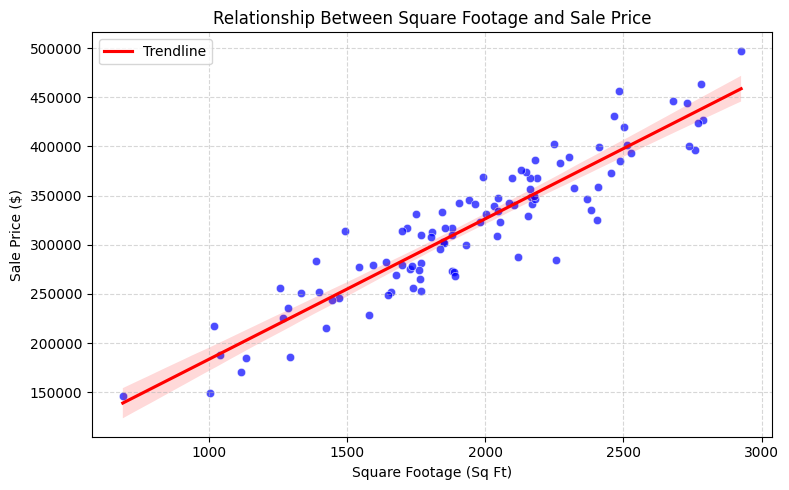

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='SquareFootage', y='SalePrice', alpha=0.7, color='blue')
sns.regplot(data=df, x='SquareFootage', y='SalePrice', scatter=False, color='red', label='Trendline')

plt.title('Relationship Between Square Footage and Sale Price')
plt.xlabel('Square Footage (Sq Ft)')
plt.ylabel('Sale Price ($)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

## 4. Analysis & Discussion

### What do the statistics tell us about the data?
* **Mean & Median:** Looking at `SquareFootage`, the mean  and median  are very close, indicating a highly symmetric, bell-shaped distribution. For `SalePrice`, the mean  and median  are also close, representing a relatively balanced distribution of home values with some spread.
* **Standard Deviation & Variance:** The standard deviation of `SalePrice` shows that individual house prices typically vary by about $80k from the average house price, indicating moderate spread.
* **Range:** The range shows the absolute limits of our sampled dataset (e.g., the difference between the largest and smallest homes).

### What does the correlation tell us about the relationship?
* The correlation coefficient between `SquareFootage` and `SalePrice` is approximately **0.91** (highly positive). This tells us that there is a strong, positive linear relationship: as the square footage of a home increases, the sale price tends to increase significantly.

### Does correlation mean causation?
* **No.** Correlation does not necessarily imply causation. While a larger square footage often directly causes a higher price because of material and land costs, correlation alone only tells us that the two variables move together. A third confounding variable (like number of bedrooms, neighborhood tier, or builder quality) could influence both variables simultaneously.

## 5. Mathematical Expression (Input &rarr; Model &rarr; Output)

Let's choose:
* **Input ($x$):** `SquareFootage`
* **Output ($y$):** `SalePrice`

### Representation:

$$\text{Square Footage } (x) \longrightarrow \boxed{\text{Function: } f(x) = \beta_0 + \beta_1(x) + \epsilon} \longrightarrow \text{Sale Price } (y)$$

Where:
* $x$ is the input variable (independent feature).
* $f(x)$ is the linear regression function estimating the price based on unit size.
* $\beta_0$ represents the base price of land/infrastructure.
* $\beta_1$ represents the price increase per additional square foot.
* $\epsilon$ represents random variation (error/noise) not explained by size alone.
* $y$ is the predicted output variable (dependent target).